AF 7-2025

# Going back through

Being laser focused on the analyses we actually want: 

* Time spent alone among different age groups
* Time spent alone by gender
* Time spent alone by gender, broken out by different categories of activities
* Leisure time alone, leisure time with others
* Time spent socializing (and playing sports) (and being on the phone), by specific 6-category codes

In [1]:
import pandas as pd
import numpy as np
import glob
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

source = "..//data//source//"
processed = "..//data//processed//"

long_glob = glob.glob(processed + "0324//atus*.csv")
print(long_glob)

a = {}

for path in long_glob: 

    name = path.split("/")[-1][4:-9]

    a[name] = pd.read_csv(path)

['..//data//processed//0324/atussum-0324.csv', '..//data//processed//0324/atusresp-0324.csv', '..//data//processed//0324/atusact-0324.csv', '..//data//processed//0324/atuscps-0324.csv', '..//data//processed//0324/atusrost-0324.csv', '..//data//processed//0324/atuswho-0324.csv']


/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/3594198132.py:24: DtypeWarning: Columns (25,26) have mixed types. Specify dtype option on import or set low_memory=False.
  a[name] = pd.read_csv(path)


In [ ]:
def weighted_average_pivot(df, df_resp, weight_column, year_col, other_weighted_group_cols, group_cols, agg_col): 

    # get the total of the weights by group 
    weighted_group_cols = year_col + other_weighted_group_cols
    weights_by_group = df_resp.groupby(weighted_group_cols)[weight_column].agg(['sum', 'count']).reset_index()
    # get the weighted sum for each group
    groupby_cols = weighted_group_cols + group_cols
    avg_by_code = df.groupby(groupby_cols)[[agg_col, weight_column]].apply(lambda a: sum(a[agg_col] * a[weight_column]) * 7/60).reset_index()

    # merge and divide out to get the averages
    abc_w = pd.merge(avg_by_code, weights_by_group, on = weighted_group_cols, how = 'left', validate='m:1')
    abc_w['avg_min_weighted'] = abc_w[0]/abc_w['sum']

    act_avg_pivot = abc_w.pivot_table(index = group_cols + other_weighted_group_cols, columns=year_col, values='avg_min_weighted', aggfunc='mean').reset_index()
    act_avg_pivot['change'] = act_avg_pivot[2024]/act_avg_pivot[2004]

    return act_avg_pivot


# Time spent alone among different age groups

let's do this for 

* under 25
* under 30 
* under 35

In [2]:
sum_variables = ["TUCASEID", # ID
                 "TUYEAR", # Year
    "TESCHENR", # School enrollment
    "TRSPPRES", # Presence of spouse
    "TUDIARYDAY", # day of week
    "TESEX", # Sex
    "TRERNWA", # Weekly earnings 
    "TEHRUSLT", # Usual weekly hours of work 
    "TESCHLVL", # school level
    "TUFNWGTP", # Weight
    "TEAGE", # Age 
    "PTDTRACE", # Race
    "PEHSPNON", # Hispanic Origin
    "PEEDUCA", # Educational attainment
    "GTMETSTA", # new metro status
    "GEMETSTA" # old metro status
]

actsum = a['sum'][sum_variables]
actsum = actsum[actsum.TUYEAR>=2004]
actsum.head()

,TUCASEID,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA
20720,20040101040003,2004,-1,3,7,1,-1,-1,-1,3.158614e+06,71,2,2,39,-1,1
20721,20040101040060,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1
20722,20040101040079,2004,2,1,7,1,64000,40,-1,7.423105e+06,29,2,2,40,-1,1
20723,20040101040080,2004,1,3,6,1,28000,40,1,1.213356e+07,16,1,2,35,-1,1
20724,20040101040110,2004,2,3,2,1,26000,40,-1,9.062125e+06,42,1,2,36,-1,1


In [3]:
# add age bins

actsum['age_bin_20'] = pd.cut(actsum.TEAGE, bins = [15, 35, 55, 75, np.inf], right =False)
actsum['age_bin_10'] = pd.cut(actsum.TEAGE, bins = [15, 25, 35, 45, 55, 65, 75, 85, np.inf], right =False)
actsum['age_bin_5'] = pd.cut(actsum.TEAGE, bins = [15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, np.inf], right =False)

In [4]:
# actually let's just merge in the respondent's data and use the alone time variable for now -- just to check

a['resp'][['TUCASEID', 'TRTALONE']].head()

alone = pd.merge(actsum, a['resp'][['TUCASEID', 'TRTALONE']], on = 'TUCASEID', how = 'left', validate = '1:1')

In [5]:
alone.head()

,TUCASEID,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA,age_bin_20,age_bin_10,age_bin_5,TRTALONE
0,20040101040003,2004,-1,3,7,1,-1,-1,-1,3.158614e+06,71,2,2,39,-1,1,"[55.0, 75.0)","[65.0, 75.0)","[70.0, 75.0)",465
1,20040101040060,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",120
2,20040101040079,2004,2,1,7,1,64000,40,-1,7.423105e+06,29,2,2,40,-1,1,"[15.0, 35.0)","[25.0, 35.0)","[25.0, 30.0)",125
3,20040101040080,2004,1,3,6,1,28000,40,1,1.213356e+07,16,1,2,35,-1,1,"[15.0, 35.0)","[15.0, 25.0)","[15.0, 20.0)",47
4,20040101040110,2004,2,3,2,1,26000,40,-1,9.062125e+06,42,1,2,36,-1,1,"[35.0, 55.0)","[35.0, 45.0)","[40.0, 45.0)",400


/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/2862796379.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sums = alone.groupby(['TUYEAR', abv]).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index()
/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/2862796379.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sums = alone.groupby(['TUYEAR', abv]).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index()
/var/folders/1j/xnm6rdks1ls738x97r5

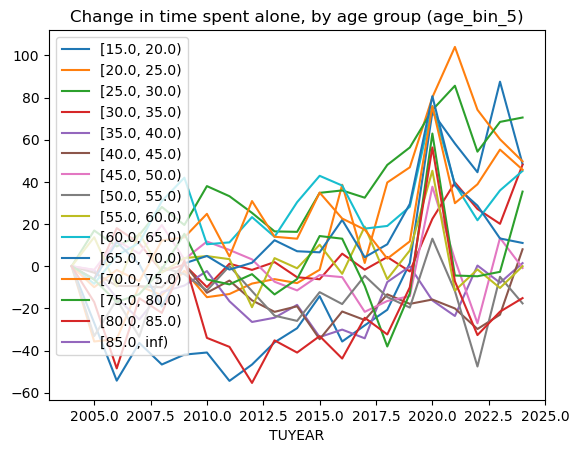

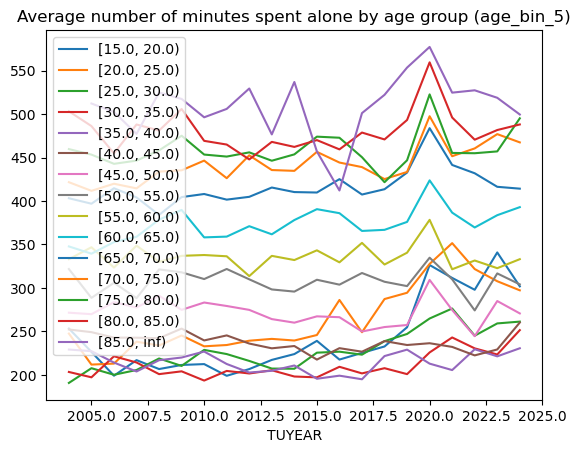

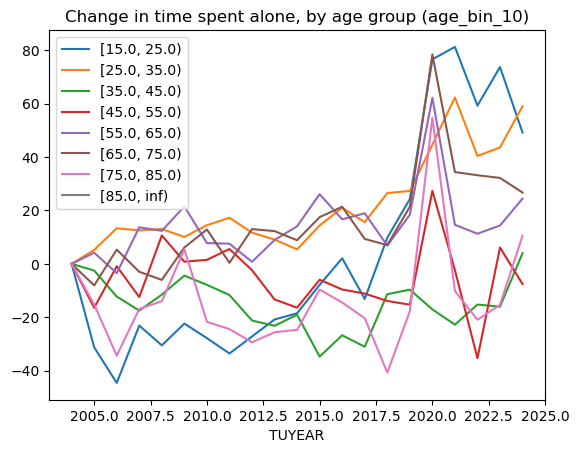

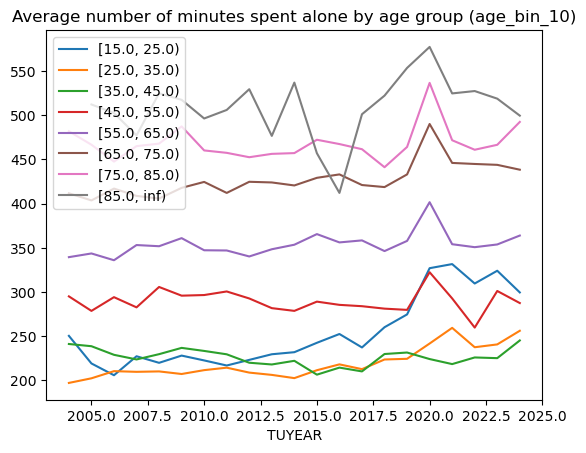

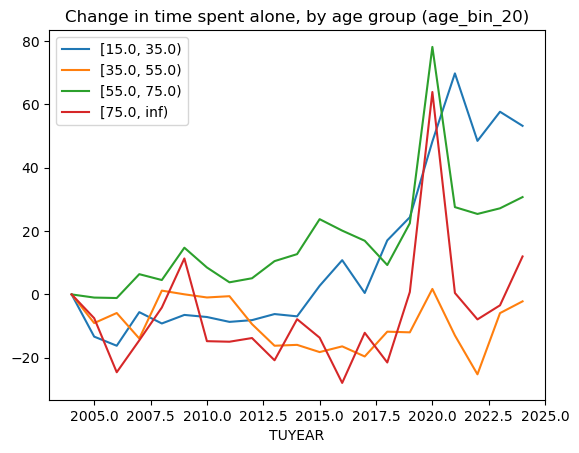

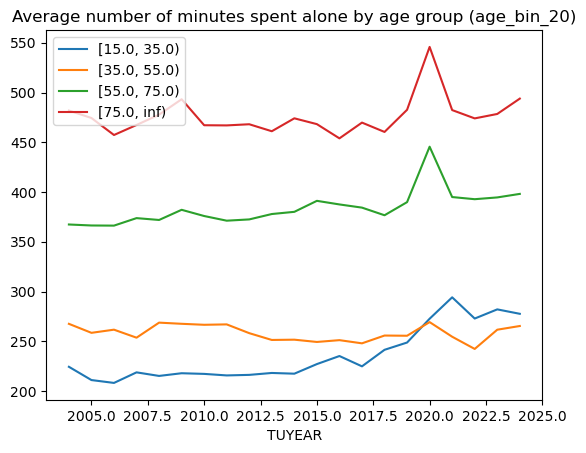

In [6]:
# i did some fiddling around with the age bins here -- starting from cutting every 5 years, then to cutting every 10, etc. I think this captures the main trend without being too overhwleming
# 

age_bin_vars = ['age_bin_5', 'age_bin_10', 'age_bin_20'] 

for abv in age_bin_vars:

    sums = alone.groupby(['TUYEAR', abv]).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index()
    sums_pivot = pd.pivot_table(sums, index = abv, columns = 'TUYEAR', values = 0, aggfunc='mean')
    sums_pivot_change = sums_pivot.apply(lambda row: row - row[2004], axis = 1)
    sums_pivot_change.T.plot()
    plt.legend(loc = 'upper left')
    plt.title(f"Change in time spent alone, by age group ({abv})")

    sums_pivot.T.plot()
    plt.title(f"Average number of minutes spent alone by age group ({abv})")
    plt.legend(loc ='upper left')


In [7]:
sums_pivot.to_csv(processed + "nb_2_age_group_alone.csv")
sums_pivot_change.to_csv(processed + "nb_2_age_group_change_alone.csv")

Let's go with people under 35 then? as a main group? 

## break it out by gender

In [8]:
alone_u35 = alone[alone.age_bin_20== pd.Interval(15, 35, closed = 'left')]
alone_u35.head()

,TUCASEID,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA,age_bin_20,age_bin_10,age_bin_5,TRTALONE
1,20040101040060,2004,2,2,1,2,-1,-1,-1,6.181583e+06,30,1,2,37,-1,1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",120
2,20040101040079,2004,2,1,7,1,64000,40,-1,7.423105e+06,29,2,2,40,-1,1,"[15.0, 35.0)","[25.0, 35.0)","[25.0, 30.0)",125
3,20040101040080,2004,1,3,6,1,28000,40,1,1.213356e+07,16,1,2,35,-1,1,"[15.0, 35.0)","[15.0, 25.0)","[15.0, 20.0)",47
12,20040101040589,2004,2,1,1,2,-1,5,-1,1.923224e+06,25,1,2,40,-1,1,"[15.0, 35.0)","[25.0, 35.0)","[25.0, 30.0)",15
16,20040101040601,2004,2,1,7,1,136538,50,-1,1.719568e+06,32,1,2,43,-1,1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",330


/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/3981293572.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  au35 = alone_u35.groupby(['TUYEAR', 'TESEX']).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index()


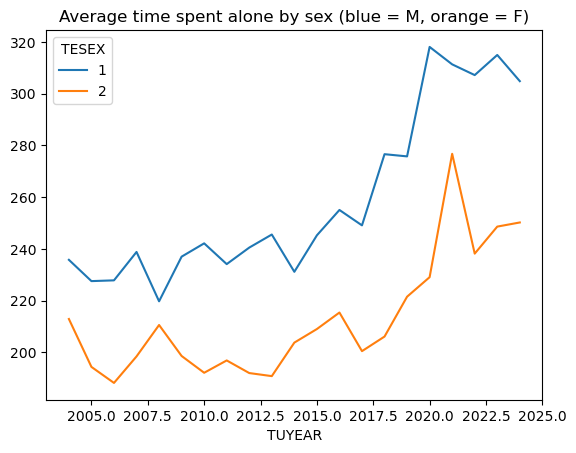

In [ ]:
au35 = alone_u35.groupby(['TUYEAR', 'TESEX']).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index()
au35_pivot = pd.pivot_table(au35, index = 'TESEX', columns = 'TUYEAR', values = 0, aggfunc='mean')
au35_pivot.T.plot()
plt.title("Average time spent alone by sex (blue = M, orange = F)")

au35_pivot.to_csv(processed + "nb_2_time_alone_u35_sex.csv")

In [10]:
alone_u35.groupby(['TUYEAR', 'TESEX'])['TUCASEID'].count()

TUYEAR  TESEX
2004    1        1743
        2        2142
2005    1        1607
        2        2121
2006    1        1585
        2        2106
2007    1        1503
        2        1941
2008    1        1565
        2        1921
2009    1        1547
        2        2005
2010    1        1597
        2        2035
2011    1        1425
        2        1902
2012    1        1467
        2        1752
2013    1        1313
        2        1611
2014    1        1324
        2        1553
2015    1        1174
        2        1488
2016    1        1147
        2        1354
2017    1        1072
        2        1291
2018    1         979
        2        1175
2019    1        1009
        2        1047
2020    1         942
        2         981
2021    1         950
        2        1065
2022    1         822
        2         848
2023    1         792
        2         845
2024    1         782
        2         764
Name: TUCASEID, dtype: int64

## "Time socializing has gone down, alone socializing has gone up" 

We're going to need to define a "social flag" and and "alone flag" 

In [11]:
a['act'].head()

# let's only pick the caseids we're already looking at 

act_in_sample = a['act'][a['act'].TUCASEID.isin(alone_u35.TUCASEID)]
print(act_in_sample.shape)
act_in_sample.head()

(1109115, 29)


,TUCASEID,TUACTIVITY_N,TUACTDUR24,TUCC5,TUCC5B,TRTCCTOT_LN,TRTCC_LN,TRTCOC_LN,TUSTARTTIM,TUSTOPTIME,TRCODEP,TRTIER1P,TRTIER2P,TUCC8,TUCUMDUR,TUCUMDUR24,TUACTDUR,TR_03CC57,TRTO_LN,TRTONHH_LN,TRTOHH_LN,TRTHH_LN,TRTNOHH_LN,TEWHERE,TUCC7,TRWBELIG,TRTEC_LN,TUEC24,TUDURSTOP
412625,20040101040060,1,90,0,0,0,0,0,04:00:00,05:30:00,120303,12,1203,97,90,90,90,-1,0,0,-1,-1,-1,1,0,-1,-1,-1,-1
412626,20040101040060,2,390,0,0,0,0,0,05:30:00,12:00:00,10101,1,101,0,480,480,390,-1,0,0,-1,-1,-1,-1,0,-1,-1,-1,-1
412627,20040101040060,3,90,0,0,0,0,0,12:00:00,13:30:00,10201,1,102,0,570,570,90,-1,0,0,-1,-1,-1,-1,0,-1,-1,-1,-1
412628,20040101040060,4,30,0,0,0,0,0,13:30:00,14:00:00,20101,2,201,0,600,600,30,-1,0,0,-1,-1,-1,1,0,-1,-1,-1,-1
412629,20040101040060,5,120,0,0,0,0,0,14:00:00,16:00:00,120101,12,1201,0,720,720,120,-1,0,0,-1,-1,-1,1,0,-1,-1,-1,-1


In [12]:
# identifying alone activities
who_alone = a['who'][((a['who'].TUWHO_CODE==18)| (a['who'].TUWHO_CODE==19))].drop(['TULINENO', 'TRWHONA', 'TUWHO_CODE'], axis =1)
who_alone['alone'] = 1

# merge in that information 
act_alone = pd.merge(act_in_sample, who_alone, on = ['TUCASEID', 'TUACTIVITY_N'], how = 'left', validate = "1:1")
act_alone.alone = act_alone.alone.fillna(0)
act_alone.head()

,TUCASEID,TUACTIVITY_N,TUACTDUR24,TUCC5,TUCC5B,TRTCCTOT_LN,TRTCC_LN,TRTCOC_LN,TUSTARTTIM,TUSTOPTIME,TRCODEP,TRTIER1P,TRTIER2P,TUCC8,TUCUMDUR,TUCUMDUR24,TUACTDUR,TR_03CC57,TRTO_LN,TRTONHH_LN,TRTOHH_LN,TRTHH_LN,TRTNOHH_LN,TEWHERE,TUCC7,TRWBELIG,TRTEC_LN,TUEC24,TUDURSTOP,alone
0,20040101040060,1,90,0,0,0,0,0,04:00:00,05:30:00,120303,12,1203,97,90,90,90,-1,0,0,-1,-1,-1,1,0,-1,-1,-1,-1,0.0
1,20040101040060,2,390,0,0,0,0,0,05:30:00,12:00:00,10101,1,101,0,480,480,390,-1,0,0,-1,-1,-1,-1,0,-1,-1,-1,-1,0.0
2,20040101040060,3,90,0,0,0,0,0,12:00:00,13:30:00,10201,1,102,0,570,570,90,-1,0,0,-1,-1,-1,-1,0,-1,-1,-1,-1,0.0
3,20040101040060,4,30,0,0,0,0,0,13:30:00,14:00:00,20101,2,201,0,600,600,30,-1,0,0,-1,-1,-1,1,0,-1,-1,-1,-1,0.0
4,20040101040060,5,120,0,0,0,0,0,14:00:00,16:00:00,120101,12,1201,0,720,720,120,-1,0,0,-1,-1,-1,1,0,-1,-1,-1,-1,0.0


In [13]:
# code the social flag

act_alone['social'] = 0
act_alone['description'] = ""

# 12 -- Socializing, Relaxing, and Leisure
act_alone.loc[act_alone.TRTIER1P == 12, 'social'] = 1
act_alone.loc[act_alone.TRTIER1P == 12, 'description'] = "Other socializing, relaxing and Leisure"

act_alone.loc[act_alone.TRCODEP == 120101, 'description'] = "Socializing and Communicating"
act_alone.loc[act_alone.TRTIER2P == 1202, 'description'] = "Attending or Hosting Social Events"
act_alone.loc[act_alone.TRCODEP == 120303, 'description'] = "Television and movies"
act_alone.loc[act_alone.TRCODEP == 120304, 'description'] = "Television and movies"
act_alone.loc[act_alone.TRCODEP == 120306, 'description'] = "Listening to/playing music (not radio)"
act_alone.loc[act_alone.TRCODEP == 120307, 'description'] = "Playing games"
act_alone.loc[act_alone.TRCODEP == 120308, 'description'] = "Computer use for leisure (exc. Games)"
act_alone.loc[act_alone.TRCODEP == 120309, 'description'] = "Arts and crafts as a hobby"
act_alone.loc[act_alone.TRCODEP == 120312, 'description'] = "Reading for personal interest"
act_alone.loc[act_alone.TRCODEP == 120301, 'description'] = "Relaxing, thinking"
act_alone.loc[act_alone.TRCODEP == 120302, 'description'] = "Tobacco and drug use"
act_alone.loc[act_alone.TRCODEP == 120305, 'description'] = "Listening to the radio"
act_alone.loc[act_alone.TRCODEP == 120401, 'description'] = "Attending performing arts"
act_alone.loc[act_alone.TRCODEP == 120403, 'description'] = "Attending movies/film"
act_alone.loc[act_alone.TRCODEP == 120499, 'description'] = "Other Arts and entertainment"

# 1301 -- Participating in Sports, Exercise, or Recreation 
act_alone.loc[act_alone.TRTIER2P == 1301, 'social'] = 1
act_alone.loc[act_alone.TRTIER2P == 1301, 'description'] = "Participating in Sports, Exercise, or Recreation"

# 1302 -- Attending Sporting/Recreational Events 
act_alone.loc[act_alone.TRTIER2P == 1302, 'social'] = 1
act_alone.loc[act_alone.TRTIER2P == 1302, 'description'] = "Attending Sporting/Recreational Events"

# 15 -- Volunteer Activities
act_alone.loc[act_alone.TRTIER1P == 15, 'social'] = 1
act_alone.loc[act_alone.TRTIER1P == 15, 'description'] = "Volunteer Activities"

# 0206 -- pet care
act_alone.loc[act_alone.TRTIER2P == 206, 'social'] = 1
act_alone.loc[act_alone.TRTIER2P == 206, 'description'] = "Animals and Pets"

# 160102 -- telephone calls to/from friends, neighbors, or acquaintances 
act_alone.loc[act_alone.TRCODEP == 160102, 'social'] = 1
act_alone.loc[act_alone.TRCODEP == 160102, 'description'] = "Telephone calls to/from friends, neighbors, or acquaintances "

In [14]:
act_alone[['alone', 'social']].value_counts()

alone  social
0.0    0         676663
1.0    0         230992
0.0    1         128131
1.0    1          73329
Name: count, dtype: int64

In [15]:
# merge in the demographic information

act_alone.head()

,TUCASEID,TUACTIVITY_N,TUACTDUR24,TUCC5,TUCC5B,TRTCCTOT_LN,TRTCC_LN,TRTCOC_LN,TUSTARTTIM,TUSTOPTIME,TRCODEP,TRTIER1P,TRTIER2P,TUCC8,TUCUMDUR,TUCUMDUR24,TUACTDUR,TR_03CC57,TRTO_LN,TRTONHH_LN,TRTOHH_LN,TRTHH_LN,TRTNOHH_LN,TEWHERE,TUCC7,TRWBELIG,TRTEC_LN,TUEC24,TUDURSTOP,alone,social,description
0,20040101040060,1,90,0,0,0,0,0,04:00:00,05:30:00,120303,12,1203,97,90,90,90,-1,0,0,-1,-1,-1,1,0,-1,-1,-1,-1,0.0,1,Television and movies
1,20040101040060,2,390,0,0,0,0,0,05:30:00,12:00:00,10101,1,101,0,480,480,390,-1,0,0,-1,-1,-1,-1,0,-1,-1,-1,-1,0.0,0,
2,20040101040060,3,90,0,0,0,0,0,12:00:00,13:30:00,10201,1,102,0,570,570,90,-1,0,0,-1,-1,-1,-1,0,-1,-1,-1,-1,0.0,0,
3,20040101040060,4,30,0,0,0,0,0,13:30:00,14:00:00,20101,2,201,0,600,600,30,-1,0,0,-1,-1,-1,1,0,-1,-1,-1,-1,0.0,0,
4,20040101040060,5,120,0,0,0,0,0,14:00:00,16:00:00,120101,12,1201,0,720,720,120,-1,0,0,-1,-1,-1,1,0,-1,-1,-1,-1,0.0,1,Socializing and Communicating


In [16]:
soc_alone = pd.merge(alone_u35, act_alone, on = 'TUCASEID', how = 'outer', validate = "1:m", indicator = True)
soc_alone._merge.value_counts()

_merge
both          1109115
left_only           0
right_only          0
Name: count, dtype: int64

In [124]:
# minutes spent alone, versus minutes spent social, over time

alone_by_person = soc_alone.groupby(['TUYEAR', 'TUCASEID', 'TUFNWGTP', 'TESEX', 'alone'])['TUACTDUR24'].sum().reset_index()
print(soc_alone[soc_alone.alone == 1]['TUCASEID'].nunique())
print(alone_u35.shape)
print("sigh, there are people that never spend time alone I guess. This complicates the weighting.")
alone_by_person.head()

52232
(58292, 20)
sigh, there are people that never spend time alone I guess. This complicates the weighting.


,TUYEAR,TUCASEID,TUFNWGTP,TESEX,alone,TUACTDUR24
0,2004,20040101040060,6.181583e+06,2,0.0,1320
1,2004,20040101040060,6.181583e+06,2,1.0,120
2,2004,20040101040079,7.423105e+06,1,0.0,1315
3,2004,20040101040079,7.423105e+06,1,1.0,125
4,2004,20040101040080,1.213356e+07,1,0.0,1393


In [126]:
# a pivot table will solve this!

abp_pivot = pd.pivot_table(alone_by_person, index = ['TUYEAR', 'TUCASEID', 'TESEX', 'TUFNWGTP'], columns = 'alone', values = 'TUACTDUR24', aggfunc = 'mean').drop(0, axis = 1).reset_index()
abp_pivot[1.0] = abp_pivot[1.0].fillna(0)
sum(abp_pivot[1.0]==0)

6060

In [150]:
abp_pivot.head()

alone,TUYEAR,TUCASEID,TESEX,TUFNWGTP,1.0
0,2004,20040101040060,2,6.181583e+06,120.0
1,2004,20040101040079,1,7.423105e+06,125.0
2,2004,20040101040080,1,1.213356e+07,47.0
3,2004,20040101040589,2,1.923224e+06,15.0
4,2004,20040101040601,1,1.719568e+06,330.0


/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/323814192.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  abp_pivot.groupby(['TUYEAR', 'TESEX']).apply(lambda x: np.average(x[1.0], weights=x.TUFNWGTP)).reset_index().pivot_table(index = 'TESEX', columns = 'TUYEAR', values = 0, aggfunc='mean').T.plot()


Text(0.5, 1.0, 'minutes spent alone')

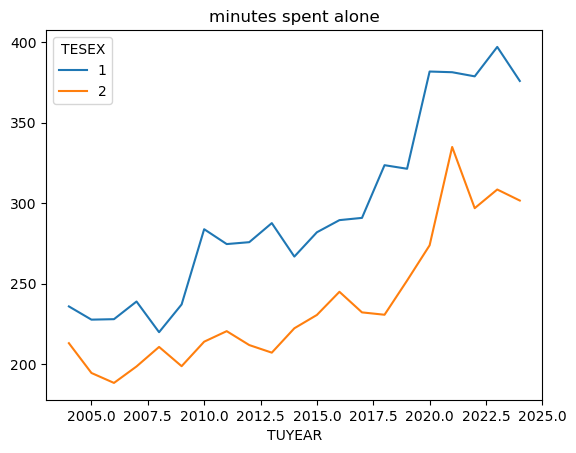

In [149]:
abp_pivot.groupby(['TUYEAR', 'TESEX']).apply(lambda x: np.average(x[1.0], weights=x.TUFNWGTP)).reset_index().pivot_table(index = 'TESEX', columns = 'TUYEAR', values = 0, aggfunc='mean').T.plot()
plt.title("minutes spent alone")

In [140]:
abp_pivot[~abp_pivot.TUCASEID.isin(alone_u35.TUCASEID)].head()

alone,TUYEAR,TUCASEID,TESEX,TUFNWGTP,1.0


In [121]:
abp_pivot.head()

alone,TUYEAR,TUCASEID,TUFNWGTP,1.0
0,2004,20040101040060,6.181583e+06,120.0
1,2004,20040101040079,7.423105e+06,125.0
2,2004,20040101040080,1.213356e+07,47.0
3,2004,20040101040589,1.923224e+06,15.0
4,2004,20040101040601,1.719568e+06,330.0


In [20]:
# minutes spent alone, versus minutes spent social, over time

social_by_person = soc_alone.groupby(['TUYEAR', 'TUCASEID', 'TUFNWGTP', 'TESEX', 'social'])['TUACTDUR24'].sum().reset_index()
print(soc_alone[soc_alone.social == 1]['TUCASEID'].nunique())
print(alone_u35.shape)
print("sigh, there are people that never spend time alone I guess. This complicates the weighting.")
social_by_person.head()

55832
(58292, 20)
sigh, there are people that never spend time alone I guess. This complicates the weighting.


,TUYEAR,TUCASEID,TUFNWGTP,TESEX,social,TUACTDUR24
0,2004,20040101040060,6.181583e+06,2,0,800
1,2004,20040101040060,6.181583e+06,2,1,640
2,2004,20040101040079,7.423105e+06,1,0,1140
3,2004,20040101040079,7.423105e+06,1,1,300
4,2004,20040101040080,1.213356e+07,1,0,950


/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/906757539.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  min_social = sbp_pivot.groupby(['TUYEAR']).apply(lambda x: np.average(x[1.0], weights=x.TUFNWGTP))


Text(0.5, 1.0, 'minutes spent doing social activities')

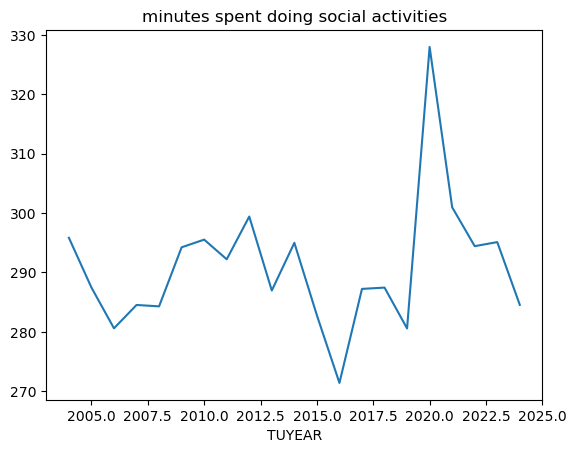

In [21]:
# a pivot table will solve this!

sbp_pivot = pd.pivot_table(social_by_person, index = ['TUYEAR', 'TUCASEID','TESEX', 'TUFNWGTP'], columns = 'social', values = 'TUACTDUR24', aggfunc = 'mean').drop(0, axis = 1).reset_index()
sbp_pivot[1.0] = sbp_pivot[1.0].fillna(0)
sum(sbp_pivot[1.0]==0)

min_social = sbp_pivot.groupby(['TUYEAR']).apply(lambda x: np.average(x[1.0], weights=x.TUFNWGTP))

min_social.to_csv(processed + "nb_2_minutes_social.csv")

min_social.plot()
plt.title("minutes spent doing social activities")

Text(0.5, 1.0, 'minutes doing social activities')

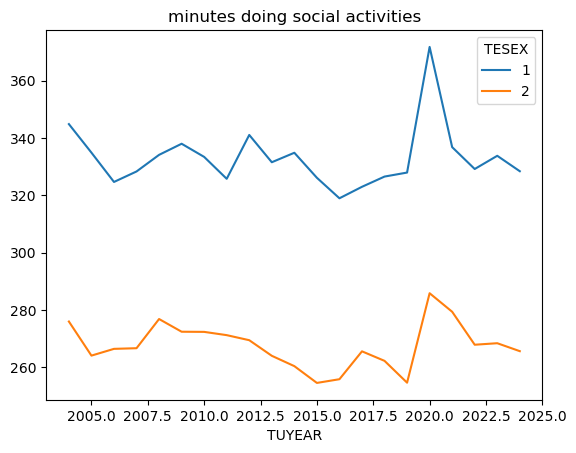

In [22]:
min_social_sex = pd.pivot_table(sbp_pivot, index='TESEX', columns = 'TUYEAR', values = 1.0, aggfunc="mean").T
min_social_sex.to_csv(processed + "nb_2_min_social_sex.csv")

min_social_sex.plot()
plt.title("minutes doing social activities")

In [23]:
# minutes spent alone, versus minutes spent social, over time

social_by_person = soc_alone.groupby(['TUYEAR', 'TUCASEID', 'TUFNWGTP', 'TESEX', 'alone', 'social'])['TUACTDUR24'].sum().reset_index()
social_by_person.alone = social_by_person.alone.astype(int)
social_by_person.social = social_by_person.social.astype(int)
social_by_person['a_s'] = social_by_person.apply(lambda row: f"{int(row.alone)}_{int(row.social)}", axis=1)
print(soc_alone[soc_alone.social == 1]['TUCASEID'].nunique())
print(alone_u35.shape)
print("sigh, there are people that never spend time alone I guess. This complicates the weighting.")
social_by_person.head()

55832
(58292, 20)
sigh, there are people that never spend time alone I guess. This complicates the weighting.


,TUYEAR,TUCASEID,TUFNWGTP,TESEX,alone,social,TUACTDUR24,a_s
0,2004,20040101040060,6.181583e+06,2,0,0,680,0_0
1,2004,20040101040060,6.181583e+06,2,0,1,640,0_1
2,2004,20040101040060,6.181583e+06,2,1,0,120,1_0
3,2004,20040101040079,7.423105e+06,1,0,0,1015,0_0
4,2004,20040101040079,7.423105e+06,1,0,1,300,0_1


/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/3371875217.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  asbp_g = asbp_pivot.groupby(['TUYEAR']).apply(lambda x: np.average(x['1_1'], weights=x.TUFNWGTP))


Text(0.5, 1.0, 'minutes spent doing social activities alone')

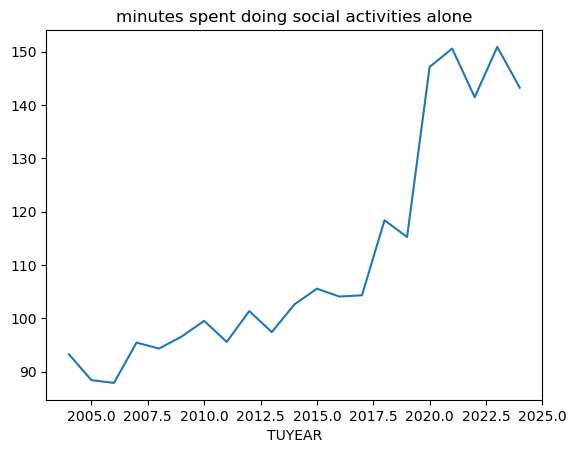

In [24]:
# a pivot table will solve this!

asbp_pivot = pd.pivot_table(social_by_person, index = ['TUYEAR', 'TUCASEID', 'TESEX', 'TUFNWGTP'], columns = ['a_s'], values = 'TUACTDUR24', aggfunc = 'mean').reset_index().fillna(0)
asbp_pivot.head()


asbp_g = asbp_pivot.groupby(['TUYEAR']).apply(lambda x: np.average(x['1_1'], weights=x.TUFNWGTP))
asbp_g.to_csv(processed + "nb_2_min_social_alone.csv")

asbp_g.plot()
plt.title("minutes spent doing social activities alone")

Text(0.5, 1.0, 'minutes spent doing social activities alone')

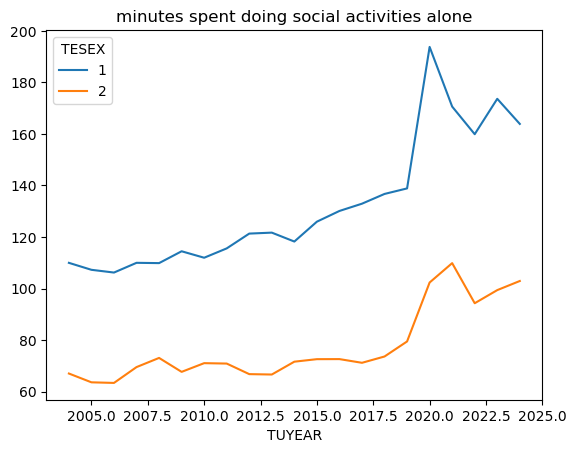

In [25]:
asbp_g_sex = pd.pivot_table(asbp_pivot, index='TESEX', columns = 'TUYEAR', values = '1_1', aggfunc="mean").T
asbp_g_sex.to_csv(processed + 'nb_2_min_social_alone_sex.csv')

asbp_g_sex.plot()

plt.title("minutes spent doing social activities alone")

In [26]:
# average each of these across each hobby over time

soc_2004 = soc_alone[soc_alone.TUYEAR==2004].groupby(['TUYEAR', 'TUCASEID', 'TUFNWGTP', 'TESEX', 'description'])['TUACTDUR24'].sum().reset_index()
soc_2004_pivot = pd.pivot_table(soc_2004, index = ['TUCASEID', 'TUFNWGTP', 'TUYEAR', 'TESEX'], columns= 'description', values = 'TUACTDUR24', aggfunc='sum').fillna(0).reset_index().drop(['TUCASEID', 'TUYEAR'], axis = 1).set_index("TUFNWGTP")

sum_04 = soc_2004_pivot.groupby("TESEX").apply(lambda sex: sex.apply(lambda col: np.average(col, weights = col.index)*7/60)).drop("TESEX", axis=1).T.sort_values(1, ascending=False)
sum_04.to_csv(processed + "nb_2_social_detailed_04.csv")

sum_04

/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/1293095435.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sum_04 = soc_2004_pivot.groupby("TESEX").apply(lambda sex: sex.apply(lambda col: np.average(col, weights = col.index)*7/60)).drop("TESEX", axis=1).T.sort_values(1, ascending=False)


TESEX,1,2
description,,
,130.322981,136.662226
Television and movies,17.692453,15.420288
Socializing and Communicating,5.228349,5.595873
"Participating in Sports, Exercise, or Recreation",3.630597,1.678358
Playing games,3.174868,0.774396
Computer use for leisure (exc. Games),1.616639,0.971734
"Relaxing, thinking",1.446231,1.275400
Reading for personal interest,0.826500,1.220659
Volunteer Activities,0.619508,0.807162


In [27]:
# average each of these across each hobby over time

soc_2024 = soc_alone[soc_alone.TUYEAR==2024].groupby(['TUYEAR', 'TUCASEID', 'TUFNWGTP', 'TESEX', 'description'])['TUACTDUR24'].sum().reset_index()
soc_2024_pivot = pd.pivot_table(soc_2024, index = ['TUCASEID', 'TUFNWGTP', 'TUYEAR', 'TESEX'], columns= 'description', values = 'TUACTDUR24', aggfunc='sum').fillna(0).reset_index().drop(['TUCASEID', 'TUYEAR'], axis = 1).set_index("TUFNWGTP")
soc_2024_pivot.groupby("TESEX").apply(lambda sex: sex.apply(lambda col: np.average(col, weights = col.index)*7/60)).drop("TESEX", axis=1).T.sort_values(1, ascending=False)

sum_24 = soc_2024_pivot.groupby("TESEX").apply(lambda sex: sex.apply(lambda col: np.average(col, weights = col.index)*7/60)).drop("TESEX", axis=1).T.sort_values(1, ascending=False)
sum_24.to_csv(processed + "nb_2_social_detailed_24.csv")

sum_24

/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/2772484222.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  soc_2024_pivot.groupby("TESEX").apply(lambda sex: sex.apply(lambda col: np.average(col, weights = col.index)*7/60)).drop("TESEX", axis=1).T.sort_values(1, ascending=False)
/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/2772484222.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence 

TESEX,1,2
description,,
,131.177912,138.454269
Television and movies,13.729642,12.137457
Playing games,8.073102,1.678094
Socializing and Communicating,3.774942,3.919619
"Participating in Sports, Exercise, or Recreation",3.482337,2.116778
Computer use for leisure (exc. Games),1.715246,2.158409
"Relaxing, thinking",1.483822,1.902440
Reading for personal interest,1.167530,0.987237
"Telephone calls to/from friends, neighbors, or acquaintances",0.726990,0.741010


In [28]:
soc_alone[soc_alone.description=="Other socializing, relaxing and Leisure"].TRCODEP.value_counts()

TRCODEP
120402    255
120313    224
120504    125
120399    125
120404    112
120311     66
120501     63
129999     13
120502     12
120503     10
120310      3
120599      2
120199      1
120405      1
Name: count, dtype: int64

## Changes in alone time across all categories of activities 

In [ ]:
activity_code_vars = ['TRCODEP', 'TRTIER1P', 'TRTIER2P']

def weighted_average_pivot(df, df_resp, weight_column, year_col, other_weighted_group_cols, group_cols, agg_col): 

    # get the total of the weights by group 
    weighted_group_cols = year_col + other_weighted_group_cols
    weights_by_group = df_resp.groupby(weighted_group_cols)[weight_column].agg(['sum', 'count']).reset_index()

    # get the weighted sum for each group
    groupby_cols = weighted_group_cols + group_cols
    avg_by_code = df.groupby(groupby_cols)[[agg_col, weight_column]].apply(lambda a: sum(a[agg_col] * a[weight_column]) * 7/60).reset_index()

    print(avg_by_code[groupby_cols].value_counts().value_counts())

    # merge and divide out to get the averages
    abc_w = pd.merge(avg_by_code, weights_by_group, on = weighted_group_cols, how = 'outer', validate='m:1', indicator=True)
    print(abc_w._merge.value_counts())
    abc_w['avg_min_weighted'] = abc_w[0]/abc_w['sum']

    # the shape of abc_w is right   
    act_avg_pivot = abc_w.pivot_table(index = group_cols + other_weighted_group_cols, columns=year_col, values='avg_min_weighted', aggfunc='mean').reset_index()
    act_avg_pivot['change'] = act_avg_pivot[2024]/act_avg_pivot[2004]

    return act_avg_pivot


In [148]:
with pd.ExcelWriter(processed + 'nb_2_alone_hours_per_week_by_sex.xlsx') as writer:

    for var in activity_code_vars: 

        f = weighted_average_pivot(soc_alone[soc_alone.alone==1], actsum[actsum.TUCASEID.isin(soc_alone.TUCASEID)], 'TUFNWGTP', ['TUYEAR'], [], [var], 'TUACTDUR24')

        f.to_excel(writer, sheet_name = var, index =None)

count
1    4186
Name: count, dtype: int64
_merge
both          4186
left_only        0
right_only       0
Name: count, dtype: int64
count
1    376
Name: count, dtype: int64
_merge
both          376
left_only       0
right_only      0
Name: count, dtype: int64
count
1    1566
Name: count, dtype: int64
_merge
both          1566
left_only        0
right_only       0
Name: count, dtype: int64


In [146]:
soc_alone[soc_alone.alone==1].TRTIER1P.value_counts()

TRTIER1P
18    100489
2      62368
12     56012
11     28743
7      12445
6       9933
5       9809
16      7286
13      5975
50      2834
3       2494
8       1619
14      1183
1       1043
4        857
15       772
9        312
10       147
Name: count, dtype: int64

In [118]:
soc_alone[soc_alone.TUCASEID==20040101040601].head()

,TUCASEID,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA,age_bin_20,age_bin_10,age_bin_5,TRTALONE,TUACTIVITY_N,TUACTDUR24,TUCC5,TUCC5B,TRTCCTOT_LN,TRTCC_LN,TRTCOC_LN,TUSTARTTIM,TUSTOPTIME,TRCODEP,TRTIER1P,TRTIER2P,TUCC8,TUCUMDUR,TUCUMDUR24,TUACTDUR,TR_03CC57,TRTO_LN,TRTONHH_LN,TRTOHH_LN,TRTHH_LN,TRTNOHH_LN,TEWHERE,TUCC7,TRWBELIG,TRTEC_LN,TUEC24,TUDURSTOP,alone,social,description,_merge
88,20040101040601,2004,2,1,7,1,136538,50,-1,1.719568e+06,32,1,2,43,-1,1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",330,1,180,0,0,0,0,0,04:00:00,07:00:00,10101,1,101,97,180,180,180,-1,0,-1,0,0,-1,-1,0,-1,-1,-1,-1,0.0,0,,both
89,20040101040601,2004,2,1,7,1,136538,50,-1,1.719568e+06,32,1,2,43,-1,1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",330,2,30,0,0,0,0,0,07:00:00,07:30:00,110101,11,1101,0,210,210,30,-1,0,-1,0,0,-1,1,0,-1,-1,-1,-1,0.0,0,,both
90,20040101040601,2004,2,1,7,1,136538,50,-1,1.719568e+06,32,1,2,43,-1,1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",330,3,90,1,0,0,0,0,07:30:00,09:00:00,30103,3,301,0,300,300,90,-1,0,-1,0,0,-1,1,0,-1,-1,-1,-1,0.0,0,,both
91,20040101040601,2004,2,1,7,1,136538,50,-1,1.719568e+06,32,1,2,43,-1,1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",330,4,30,0,0,0,0,0,09:00:00,09:30:00,50101,5,501,0,330,330,30,-1,0,-1,0,0,-1,1,0,-1,-1,-1,-1,0.0,0,,both
92,20040101040601,2004,2,1,7,1,136538,50,-1,1.719568e+06,32,1,2,43,-1,1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",330,5,60,0,0,0,0,0,09:30:00,10:30:00,10201,1,102,0,390,390,60,-1,0,-1,0,0,-1,-1,0,-1,-1,-1,-1,0.0,0,,both


In [77]:
print(actsum[actsum.TUCASEID.isin(soc_alone.TUCASEID)].TUCASEID.nunique())
print(soc_alone[soc_alone.alone==1]['TUCASEID'].nunique())

58292
52232


In [93]:
actsum[actsum.TUCASEID==20241212242273]

,TUCASEID,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA,age_bin_20,age_bin_10,age_bin_5
252804,20241212242273,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)"


In [94]:
soc_alone[soc_alone.TUCASEID==20241212242273]

,TUCASEID,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA,age_bin_20,age_bin_10,age_bin_5,TRTALONE,TUACTIVITY_N,TUACTDUR24,TUCC5,TUCC5B,TRTCCTOT_LN,TRTCC_LN,TRTCOC_LN,TUSTARTTIM,TUSTOPTIME,TRCODEP,TRTIER1P,TRTIER2P,TUCC8,TUCUMDUR,TUCUMDUR24,TUACTDUR,TR_03CC57,TRTO_LN,TRTONHH_LN,TRTOHH_LN,TRTHH_LN,TRTNOHH_LN,TEWHERE,TUCC7,TRWBELIG,TRTEC_LN,TUEC24,TUDURSTOP,alone,social,description,_merge
1109090,20241212242273,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",490,1,300,0,0,0,-1,0,04:00:00,09:00:00,10101,1,101,97,300,300,300,-1,-1,-1,-1,-1,-1,-1,0,-1,-1,-1,2,0.0,0,,both
1109091,20241212242273,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",490,2,10,0,0,0,-1,0,09:00:00,09:10:00,160105,16,1601,0,310,310,10,-1,-1,-1,-1,-1,-1,1,0,-1,-1,-1,1,1.0,0,,both
1109092,20241212242273,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",490,3,30,0,0,0,-1,0,09:10:00,09:40:00,10201,1,102,0,340,340,30,-1,-1,-1,-1,-1,-1,-1,0,-1,-1,-1,1,0.0,0,,both
1109093,20241212242273,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",490,4,10,0,0,0,-1,0,09:40:00,09:50:00,180807,18,1808,0,350,350,10,-1,-1,-1,-1,-1,-1,12,0,-1,-1,-1,1,1.0,0,,both
1109094,20241212242273,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",490,5,10,0,0,0,-1,0,09:50:00,10:00:00,80701,8,807,0,360,360,10,-1,-1,-1,-1,-1,-1,11,0,-1,-1,-1,1,0.0,0,,both
1109095,20241212242273,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",490,6,10,0,0,0,-1,0,10:00:00,10:10:00,180807,18,1808,0,370,370,10,-1,-1,-1,-1,-1,-1,12,0,-1,-1,-1,1,1.0,0,,both
1109096,20241212242273,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",490,7,60,0,0,0,-1,0,10:10:00,11:10:00,20101,2,201,0,430,430,60,-1,-1,-1,-1,-1,-1,1,0,-1,-1,-1,1,1.0,0,,both
1109097,20241212242273,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",490,8,30,0,0,0,-1,0,11:10:00,11:40:00,20902,2,209,0,460,460,30,-1,-1,-1,-1,-1,-1,1,0,-1,-1,-1,1,1.0,0,,both
1109098,20241212242273,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",490,9,15,0,0,0,-1,0,11:40:00,11:55:00,20201,2,202,0,475,475,15,-1,-1,-1,-1,-1,-1,1,0,-1,-1,-1,1,1.0,0,,both
1109099,20241212242273,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",490,10,15,0,0,0,-1,0,11:55:00,12:10:00,110101,11,1101,0,490,490,15,-1,-1,-1,-1,-1,-1,1,0,-1,-1,-1,1,1.0,0,,both


In [92]:
soc_alone.tail()

,TUCASEID,TUYEAR,TESCHENR,TRSPPRES,TUDIARYDAY,TESEX,TRERNWA,TEHRUSLT,TESCHLVL,TUFNWGTP,TEAGE,PTDTRACE,PEHSPNON,PEEDUCA,GTMETSTA,GEMETSTA,age_bin_20,age_bin_10,age_bin_5,TRTALONE,TUACTIVITY_N,TUACTDUR24,TUCC5,TUCC5B,TRTCCTOT_LN,TRTCC_LN,TRTCOC_LN,TUSTARTTIM,TUSTOPTIME,TRCODEP,TRTIER1P,TRTIER2P,TUCC8,TUCUMDUR,TUCUMDUR24,TUACTDUR,TR_03CC57,TRTO_LN,TRTONHH_LN,TRTOHH_LN,TRTHH_LN,TRTNOHH_LN,TEWHERE,TUCC7,TRWBELIG,TRTEC_LN,TUEC24,TUDURSTOP,alone,social,description,_merge
1109110,20241212242273,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",490,21,60,0,0,0,-1,0,19:55:00,20:55:00,10201,1,102,0,1015,1015,60,-1,-1,-1,-1,-1,-1,-1,0,-1,-1,-1,1,0.0,0,,both
1109111,20241212242273,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",490,22,15,0,0,0,-1,0,20:55:00,21:10:00,20203,2,202,0,1030,1030,15,-1,-1,-1,-1,-1,-1,1,0,-1,-1,-1,1,1.0,0,,both
1109112,20241212242273,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",490,23,230,0,0,0,-1,0,21:10:00,01:00:00,10101,1,101,0,1260,1260,230,-1,-1,-1,-1,-1,-1,-1,0,-1,-1,-1,2,0.0,0,,both
1109113,20241212242273,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",490,24,5,0,0,0,-1,0,01:00:00,01:05:00,10201,1,102,0,1265,1265,5,-1,-1,-1,-1,-1,-1,-1,0,-1,-1,-1,1,0.0,0,,both
1109114,20241212242273,2024,2,1,2,2,180000,40,-1,1.027231e+07,30,1,2,41,1,-1,"[15.0, 35.0)","[25.0, 35.0)","[30.0, 35.0)",490,25,175,0,0,0,-1,0,01:05:00,08:30:00,10101,1,101,0,1710,1440,445,-1,-1,-1,-1,-1,-1,-1,0,-1,-1,-1,2,0.0,0,,both


## gender and age

/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/4107249034.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sums = alone.groupby(['TUYEAR', 'TESEX', abv]).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index()
/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/4107249034.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sums = alone.groupby(['TUYEAR', 'TESEX', abv]).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index()
/var/folders/1j/x

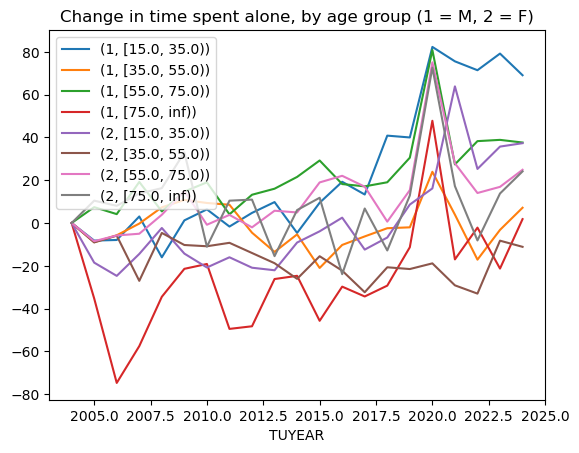

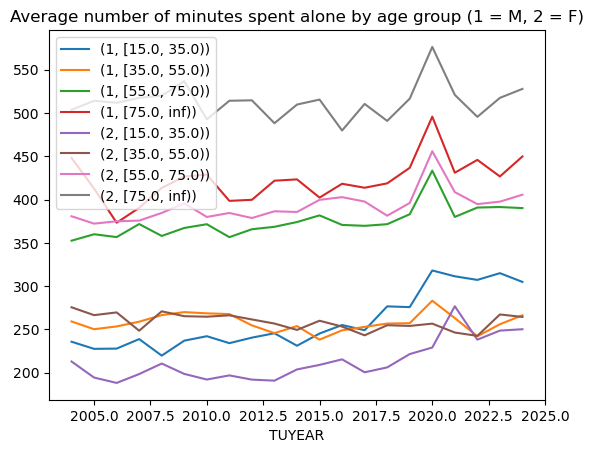

In [103]:
abv = "age_bin_20"

sums = alone.groupby(['TUYEAR', 'TESEX', abv]).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index()
sums_pivot = pd.pivot_table(sums, index = ['TESEX', abv], columns = 'TUYEAR', values = 0, aggfunc='mean')
sums_pivot_change = sums_pivot.apply(lambda row: row - row[2004], axis = 1)
sums_pivot_change.T.plot()
plt.legend(loc = 'upper left')
plt.title(f"Change in time spent alone, by age group (1 = M, 2 = F)")

sums_pivot.T.plot()
plt.title(f"Average number of minutes spent alone by age group (1 = M, 2 = F)")
plt.legend(loc ='upper left')

/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/2506717587.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sums = alone.groupby(['TUYEAR', 'TESEX']).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index()


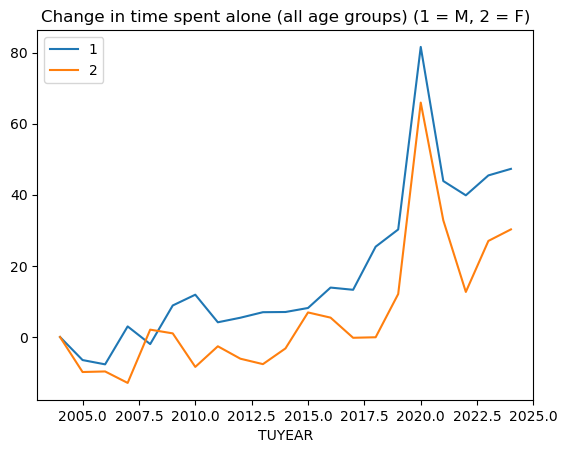

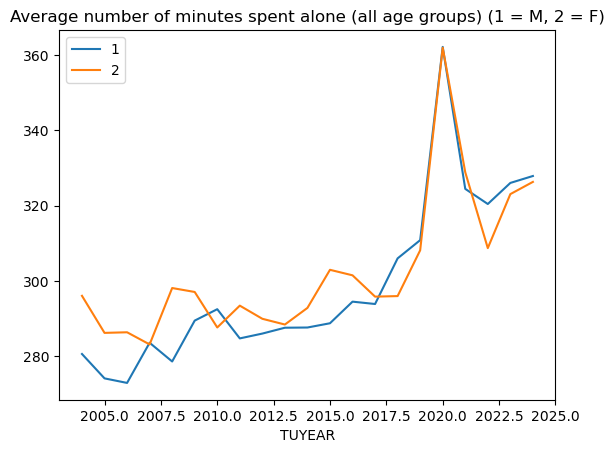

In [132]:
sums = alone.groupby(['TUYEAR', 'TESEX']).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index()
sums_pivot = pd.pivot_table(sums, index = ['TESEX'], columns = 'TUYEAR', values = 0, aggfunc='mean')
sums_pivot_change = sums_pivot.apply(lambda row: row - row[2004], axis = 1)
sums_pivot_change.T.plot()
plt.legend(loc = 'upper left')
plt.title(f"Change in time spent alone (all age groups) (1 = M, 2 = F)")

sums_pivot.T.plot()
plt.title(f"Average number of minutes spent alone (all age groups) (1 = M, 2 = F)")
plt.legend(loc ='upper left')

In [ ]:
sums_pivot = pd.pivot_table(sums, index = ['TESEX'], columns = 'TUYEAR', values = 0, aggfunc='mean')
sums_pivot.head()

TUYEAR,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
TESEX,,,,,,,,,,,,,,,,,,,,,
1,280.594976,274.113572,272.907384,283.576013,278.601676,289.464111,292.493739,284.736134,286.017710,287.572919,287.627936,288.757836,294.498239,293.873713,305.997715,310.838288,362.173580,324.459056,320.440981,326.039381,327.881348
2,296.047887,286.201801,286.362728,283.136287,298.117184,297.070915,287.639699,293.438931,289.945742,288.419860,292.837411,302.958321,301.494649,295.832057,295.977770,308.139059,361.967878,328.874707,308.723578,323.069046,326.312501


## Tracking cohorts

In [39]:
alone['BYEAR'] = alone['TUYEAR'] - alone['TEAGE']
alone['BYEAR'].describe()

count    232088.000000
mean       1964.423482
std          18.287992
min        1920.000000
25%        1951.000000
50%        1965.000000
75%        1979.000000
max        2009.000000
Name: BYEAR, dtype: float64

In [42]:
alone['birth_cohort'] = pd.cut(alone.BYEAR, bins = [1960, 1970, 1980, 1990, 2000, 2010], right = False)
alone['birth_cohort'].value_counts()

birth_cohort
[1960, 1970)    43293
[1970, 1980)    40795
[1980, 1990)    32939
[1990, 2000)    17474
[2000, 2010)     3687
Name: count, dtype: int64

/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/785522111.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sums = alone.groupby(['TUYEAR', 'birth_cohort']).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index()
/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/785522111.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sums = alone.groupby(['TUYEAR', 'birth_cohort']).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index()
/var/folders/1j

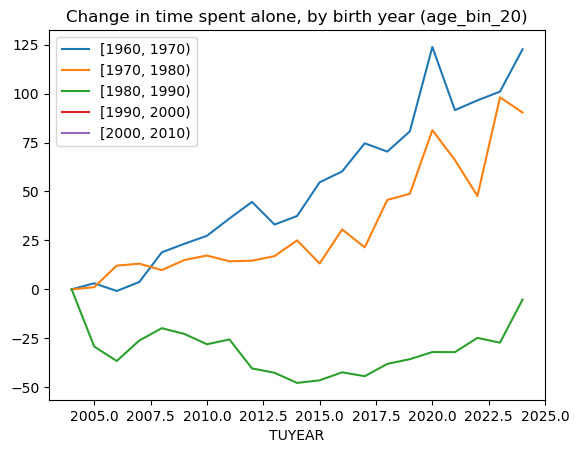

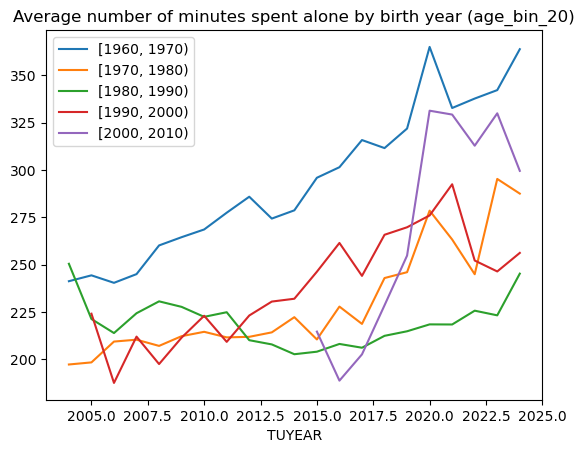

In [45]:
sums = alone.groupby(['TUYEAR', 'birth_cohort']).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index()
sums_pivot = pd.pivot_table(sums, index = 'birth_cohort', columns = 'TUYEAR', values = 0, aggfunc='mean')
sums_pivot_change = sums_pivot.apply(lambda row: row - row[2004], axis = 1)
sums_pivot_change.T.plot()
plt.legend(loc = 'upper left')
plt.title(f"Change in time spent alone, by birth year ({abv})")

sums_pivot.T.plot()
plt.title(f"Average number of minutes spent alone by birth year ({abv})")
plt.legend(loc ='upper left')


/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/4219459405.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sums = alone.groupby(['TEAGE', 'birth_cohort']).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index()
/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/4219459405.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sums = alone.groupby(['TEAGE', 'birth_cohort']).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index()
/var/folders/1j

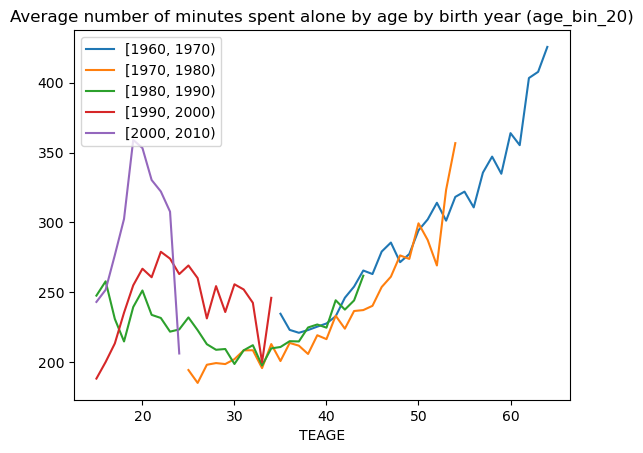

In [48]:
sums = alone.groupby(['TEAGE', 'birth_cohort']).apply(lambda x: np.average(x.TRTALONE, weights=x.TUFNWGTP)).reset_index()
sums_pivot = pd.pivot_table(sums, index = 'birth_cohort', columns = 'TEAGE', values = 0, aggfunc='mean')

sums_pivot.T.plot()
plt.title(f"Average number of minutes spent alone by age by birth year ({abv})")
plt.legend(loc ='upper left')


In [49]:
alone.pivot_table(index = 'birth_cohort', columns = 'TEAGE', values = 'TUCASEID', aggfunc='count')

/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/2859321268.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  alone.pivot_table(index = 'birth_cohort', columns = 'TEAGE', values = 'TUCASEID', aggfunc='count')


TEAGE,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,85
birth_cohort,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"[1960, 1970)",0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,273,576,890,1140,1432,1677,2004,2200,2495,2616,2498,2311,2330,2167,2032,1885,1833,1698,1626,1593,1534,1242,1098,1030,861,718,623,426,327,158,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
"[1970, 1980)",0,0,0,0,0,0,0,0,0,0,155,385,584,801,1015,1327,1670,1887,2236,2553,2447,2414,2420,2263,2280,2156,1939,1860,1792,1612,1464,1243,1037,905,675,575,461,328,233,78,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
"[1980, 1990)",190,427,737,587,562,620,708,958,1197,1248,1469,1545,1703,1803,1787,1835,1886,1857,1757,1642,1634,1555,1266,1072,911,740,562,361,200,120,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
"[1990, 2000)",1474,2039,1739,1181,882,820,735,763,859,906,946,874,881,790,693,597,493,382,288,132,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
"[2000, 2010)",718,799,629,411,291,248,209,170,145,67,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


/var/folders/1j/xnm6rdks1ls738x97r5qy2k00000gn/T/ipykernel_8315/2354624941.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  sums_pivot = pd.pivot_table(sums, index = 'birth_cohort', columns = 'TEAGE', values = 0, aggfunc='count')


TEAGE,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64
birth_cohort,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"[1960, 1970)",0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
"[1970, 1980)",0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0
"[1980, 1990)",1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
"[1990, 2000)",1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
"[2000, 2010)",1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
